## Overview
### Context
---
"You are a Senior Business Intelligence Analyst supporting the Payment Services team of an e-commerce platform.
The Business team wants to grow usage of strategic payment methods such as Wallet and BNPL, while the e-commerce platform also needs to maintain healthy order growth, user retention, seller participation, and profitability."

### Task
---
"You are provided with six months of order-level data. 

Your task is to analyze:

    - buyer
    - seller
    - category
    - payment behavior 

to help management decide:
    
<b style="color: red;">Which payment services should the company prioritize, for which user segments, and under what subsidy or growth strategy?</b>

>[!Notes]
>
> "Consider various factors and think critically about how the data can guide decision
>
> Feel free to propose any strategy derived from your analysis.
>
> Present your results and recommendations within 10 slides."

## Data

[data-case-study](raw_data/case_study_raw_data.csv)


### Data-Dictionary
| Field Name | Description | Sample Data |
| --- | --- | --- |
| **create_date** | The date when the order was placed. | 2024-05-20 |
| **order_id** | Unique identifier for each order. | CBZZWZ7C7CW7X5XW8X |
| **user_id** | Unique identifier for the user who placed the order. | A064540 |
| **state** | The user's city or address. | Hà Nội |
| **gender** | The gender of the user placing the order. | female |
| **category** | The product category of the item(s) purchased (e.g., electronics). | Beauty |
| **gross_merchant_value** | The total value of the order before any discounts. | 9 |
| **net_merchant_value** | The total value of the order after applying platform discounts. | 8.18 |
| **platform_discount** | The discount offered by the e-commerce platform (if any) on the order. | 0.82 |
| **seller_discount** | The discount offered by the seller (if any) on the order. | 0.45 |
| **user_payment_fee** | The fee charged to the buyer for the payment method used. | 0.13 |
| **payment_method** | The method used by the buyer to pay (e.g., BNPL, credit card, wallet). | BNPL |
| **total_user_payment** | The final amount paid by the buyer after all discounts and fees are applied. | 7.78 |


## DataFrame Config

In [30]:
import pandas as pd
import matplotlib.pyplot as plt


data_path = "raw_data/case_study_raw_data.csv"
df_case_study = pd.read_csv(data_path)

## Start Analysing

### Up-coming Question

### 1. What are segmenation of customer are in the dataset ? 
    according to:
        - gmv
        - nmv
        - discount (platform_discount + seller_discount)
        - payment-method 
        - last_order

In [2]:
import pandas as pd
import numpy as np

df_case_study['create_date'] = pd.to_datetime(df_case_study['create_date'])

df_case_study['is_bnpl'] = df_case_study['payment_method'] == 'BNPL'
df_case_study['is_wallet'] = df_case_study['payment_method'] == 'Wallet'
df_case_study['total_discount'] = df_case_study['platform_discount'] + df_case_study['seller_discount']

df_user_stats = df_case_study.groupby('user_id').agg(
    order=('order_id', 'nunique'),
    nmv=('net_merchant_value', 'sum'),
    total_discount_sum=('total_discount', 'sum'),
    gmv_sum=('gross_merchant_value', 'sum'),
    bnpl_order=('is_bnpl', 'sum'),
    wallet_order=('is_wallet', 'sum'),
    last_order=('create_date', 'max')
).reset_index()
df_user_stats['avg_basket'] = df_user_stats['nmv'] / df_user_stats['order']
df_user_stats['discount_pct'] = (100.0 * df_user_stats['total_discount_sum']) / df_user_stats['gmv_sum']
df_user_stats.to_csv("analyse_data_support/user_stats.csv", index=False)

### 2. Assumptions for User Segmentation by User-Id

* **`new_user`**: The user has completed exactly 1 order.
* **`repeat_buyer`**: The user has completed more than 1 order.
* **`high_value_user`**: The user falls into the top 10% of all customers based on their total Net Merchant Value (NMV).
* **`BNPL_user`**: Buy Now, Pay Later (BNPL) was used for at least 50% of the user's total orders.
* **`wallet_user`**: A digital wallet was used for at least 50% of the user's total orders.
* **`discount_sensitive_user`**: The user's total combined discounts (platform + seller) amount to 10% or more of their total Gross Merchant Value (GMV).
* **`dormant_user`**: The user has not placed an order in 30 days or more, calculated relative to the most recent transaction date in the entire dataset.

In [3]:
df_segmented = df_user_stats.copy()

nmv_rank = df_segmented['nmv'].rank(method='first', ascending=False)
df_segmented['value_decile'] = pd.qcut(nmv_rank, q=10, labels=False) + 1 

as_of = df_segmented['last_order'].max()
df_segmented['days_since_last'] = (as_of - df_segmented['last_order']).dt.days

df_segmented['nmv'] = df_segmented['nmv'].round(2)
df_segmented['avg_basket'] = df_segmented['avg_basket'].round(2)
df_segmented['discount_pct'] = df_segmented['discount_pct'].round(2)

# Apply segments
df_segmented['seg_frequency'] = np.where(df_segmented['order'] == 1, 'new_user', 'repeat_buyer')
df_segmented['seg_high_value_user'] = np.where(df_segmented['value_decile'] == 1, 1, 0)
df_segmented['seg_bnpl_user'] = np.where(df_segmented['bnpl_order'] >= df_segmented['order'] * 0.5, 1, 0)
df_segmented['seg_wallet_user'] = np.where(df_segmented['wallet_order'] >= df_segmented['order'] * 0.5, 1, 0)
df_segmented['seg_discount_sensitive_user'] = np.where(df_segmented['discount_pct'] >= 10, 1, 0)
df_segmented['seg_dormant_user'] = np.where(df_segmented['days_since_last'] >= 30, 1, 0)

final_cols = [
    'user_id', 
    'order', 
    'nmv', 
    'avg_basket', 
    'discount_pct', 
    'days_since_last',
    'seg_frequency', 
    'seg_high_value_user', 
    'seg_bnpl_user', 
    'seg_wallet_user', 
    'seg_discount_sensitive_user', 
    'seg_dormant_user'
]

df_segmented = df_segmented[final_cols].sort_values('nmv', ascending=False)
df_segmented.to_csv("analyse_data_support/user_segmentation.csv", index=False)

### Profit Calculation

> [!Assumption]
>
> Tổng doanh thu nhận được trên từng đơn hàng (Liệu còn nguồn doanh thu nào khác từ merchant hay không i.e., commission --> không)

_Cách_tính_PnL: Platform (Monee)_

- **Cost:**
    - platform_discount

- **Revenue:**
    - user_payment_fee

In [50]:
df_profit = df_case_study.copy()
# calculate the value base on the assumption
df_profit['profit'] = df_profit['user_payment_fee'] - df_profit['platform_discount']
# mapping with the segmentation
df_profit_with_category = (
    df_profit.merge(
        right=df_segmented,
        how="left",
        on="user_id"
    )
)
# category to views
df_pnl_group_cat = (
    df_profit_with_category.groupby(
        [
            "category", 
            "payment_method",
            "state",
            "seg_frequency", 
            "seg_high_value_user", 
            "seg_bnpl_user",
            "seg_wallet_user",
            "seg_discount_sensitive_user",
            "seg_dormant_user"
        ],
        dropna=False
    ).agg(
        profit=("profit", "sum"),
        cost=("platform_discount", "sum")
    ).reset_index()
)
df_pnl_group_cat.to_csv("analyse_data_support/pnl_group_cat.csv",index=False)
df_profit_with_category.to_csv("analyse_data_support/profit_with_category.csv", index=False)

### Background - Data Study

In [ ]:
df_master_data = df_profit_with_category.copy()
df_master_data['is_cost_greater_than_revenue'] = np.where(
    df_master_data['platform_discount'] > df_master_data['profit'], 1, 0
)

### Sumary profit-discount (both platform discount - seller discount)

Result: 

|  | user_payment_fee | platform_discount | total_user | total_order | total_gmv |
| --- | --- | --- | --- | --- | --- |
| **Summary** | 2162.773 | 5519.276 | 500 | 9935| 70067.995309 |

In [35]:
df_summary_in_gen = df_master_data.groupby(lambda x: 'Summary').agg(
    user_payment_fee=('user_payment_fee', 'sum'),
    platform_discount=('platform_discount', 'sum'),
    total_user=('user_id', 'nunique'),
    total_order=('order_id', 'count'),
    total_gmv=('gross_merchant_value', 'sum')
)

### Charateristics of 5 payment-method in category

Dưới đây là dữ liệu của bạn được chuyển đổi sang định dạng bảng Markdown để dễ đọc và phù hợp cho báo cáo:

| payment_method | share_in_total_order (%) | AOV | discount_per_order | fee_per_order | net_position_per_order |
| --- | --- | --- | --- | --- | --- |
| **BNPL** | 18.802214 | 7.194252 | 0.739449 | 0.104317 | -0.635132 |
| **Cash** | 37.533971 | 5.275525 | 0.508252 | 0.105511 | -0.402741 |
| **Credit** | 10.870659 | 8.502965 | 0.645112 | 0.382633 | -0.262478 |
| **Credit Installment** | 2.878712 | 41.560982 | 0.254460 | 3.615805 | 3.361345 |
| **Wallet** | 29.914444 | 5.345578 | 0.495700 | 0.042765 | -0.452935 |

---

1. **Credit Installment (Gánh team lợi nhuận):** Dù chỉ chiếm chưa tới 3% tổng số đơn hàng, nhưng AOV của nhóm này cao vượt trội (41.5), chi phí nền tảng bỏ ra (discount) rất thấp (0.25) và đặc biệt là **thu phí rất cao (fee = 3.6)**. Đây là phương thức duy nhất có Net Vị Thế Dương (+3.36/đơn).
2. **Ví điện tử (Wallet) & Tiền mặt (Cash) - Game Volume, Lỗ đậm:** Hai phương thức này chiếm tổng cộng hơn 67% số đơn hàng. AOV của chúng thấp nhất (đều khoảng 5.3). Đáng chú ý là Wallet thu phí người dùng cực thấp (0.04) nhưng lại chiết khấu khá nhiều (0.49), dẫn đến lỗ -0.45/đơn.
3. **Mua Trước Trả Sau (BNPL) - "Đốt" tiền nhiều nhất:** Dù AOV có nhỉnh hơn một chút (7.19), nhưng đây là phương thức sàn phải tung discount nặng tay nhất (0.73/đơn), dẫn đến khoản lỗ ròng trên mỗi đơn lớn nhất (-0.63/đơn). Sàn đang "đổ máu" để nuôi thói quen BNPL của người dùng.


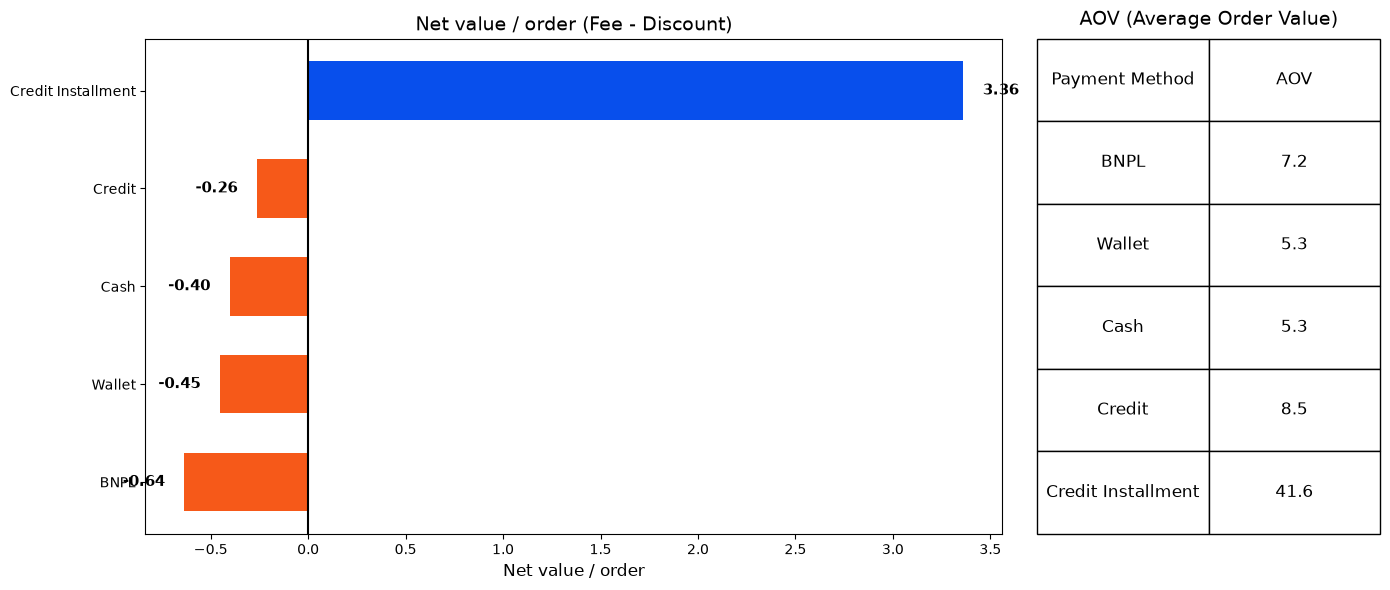

In [57]:
df_payment_method_in_category = (
    df_master_data.groupby(["payment_method"]).agg(
        total_cost_big_rev=('is_cost_greater_than_revenue', 'sum'),
        total_order=('order_id', 'count'),
        total_gmv=('gross_merchant_value', 'sum'),
        platform_discount=('platform_discount', 'sum'),
        seller_discount=('seller_discount', 'sum'),
        user_payment_fee=('user_payment_fee', 'sum'),
        total_nmv=('net_merchant_value', 'sum')
    ).reset_index()
)

df_payment_method_in_category['share_in_total_order (%)'] = (
    df_payment_method_in_category['total_order'] / df_payment_method_in_category['total_order'].sum() * 100
)

df_payment_method_in_category['AOV'] = (
    df_payment_method_in_category['total_gmv'] / df_payment_method_in_category['total_order']
)

df_payment_method_in_category['discount_per_order'] = (
    df_payment_method_in_category['platform_discount'] / df_payment_method_in_category['total_order']
)

df_payment_method_in_category['fee_per_order'] = (
    df_payment_method_in_category['user_payment_fee'] / df_payment_method_in_category['total_order']
)

df_payment_method_in_category['net_position_per_order'] = (
    df_payment_method_in_category['fee_per_order'] - df_payment_method_in_category['discount_per_order']
)
df_payment_method_in_category['gain_loss'] = (
    df_payment_method_in_category['user_payment_fee'] - df_payment_method_in_category['platform_discount']
)


### Is BNPL/Wallet users is low-value customer ?

###  1. việc lỗ đó có xuất phát từ discount-voucher của nhóm khách hàng voucher-hunter không
        - classify:
            profit n loss: trên 2 tệp
                - khách săn sale
                - khách không săn sale

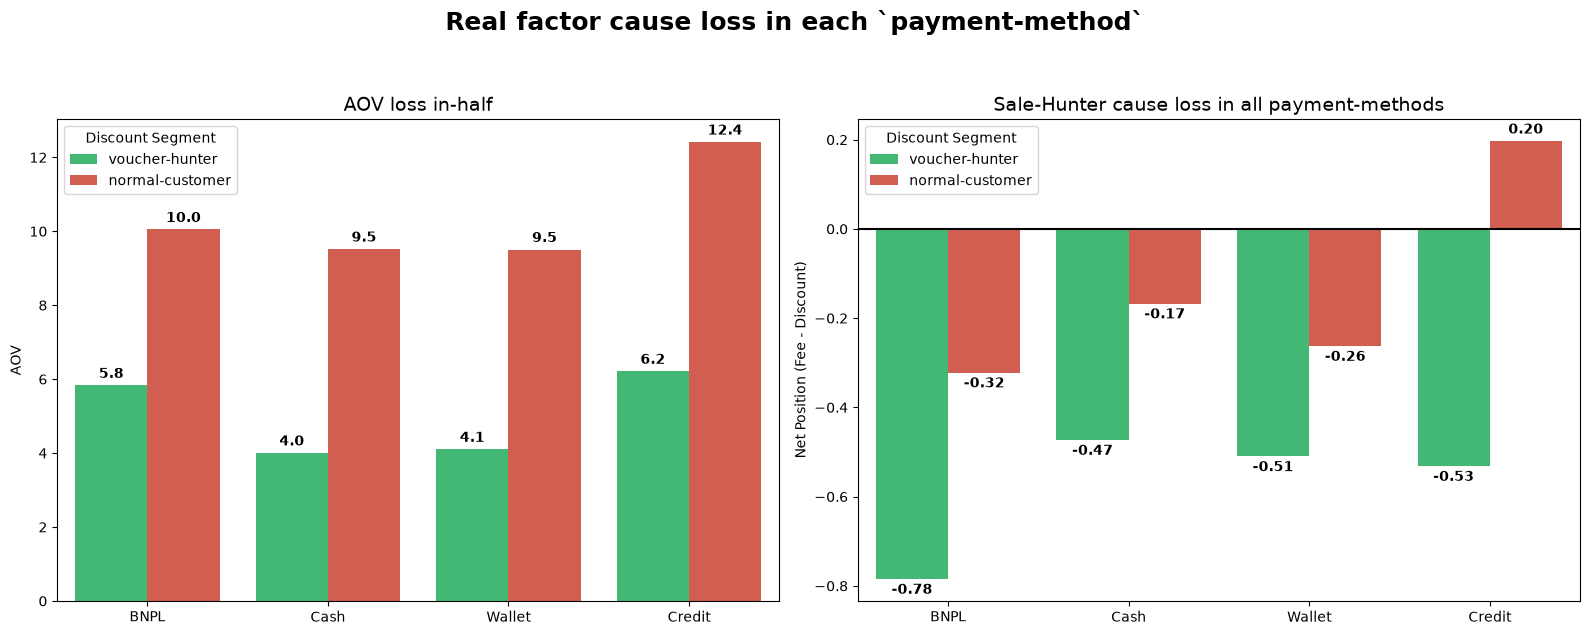

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df = df_master_data.copy()

df_viz = df[df['payment_method'] != 'Credit Installment'].copy()
df_viz['net_position'] = df_viz['user_payment_fee'] - df_viz['platform_discount']
df_viz['Discount Segment'] = df_viz['seg_discount_sensitive_user'].map({0: 'normal-customer', 1: 'voucher-hunter'})

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Real factor cause loss in each `payment-method`', fontsize=18, fontweight='bold', y=1.05)

sns.barplot(data=df_viz, x='payment_method', y='gross_merchant_value', hue='Discount Segment', 
            ax=axes[0], palette=['#2ecc71', '#e74c3c'], errorbar=None)
axes[0].set_title('AOV loss in-half', fontsize=14)
axes[0].set_xlabel('')
axes[0].set_ylabel('AOV')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.1f', padding=3, fontweight='bold')

sns.barplot(data=df_viz, x='payment_method', y='net_position', hue='Discount Segment', 
            ax=axes[1], palette=['#2ecc71', '#e74c3c'], errorbar=None)
axes[1].set_title('Sale-Hunter cause loss in all payment-methods', fontsize=14)
axes[1].set_xlabel('')
axes[1].set_ylabel('Net Position (Fee - Discount)')
axes[1].axhline(0, color='black', linewidth=1.5)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.2f', padding=3, fontweight='bold')

plt.tight_layout()

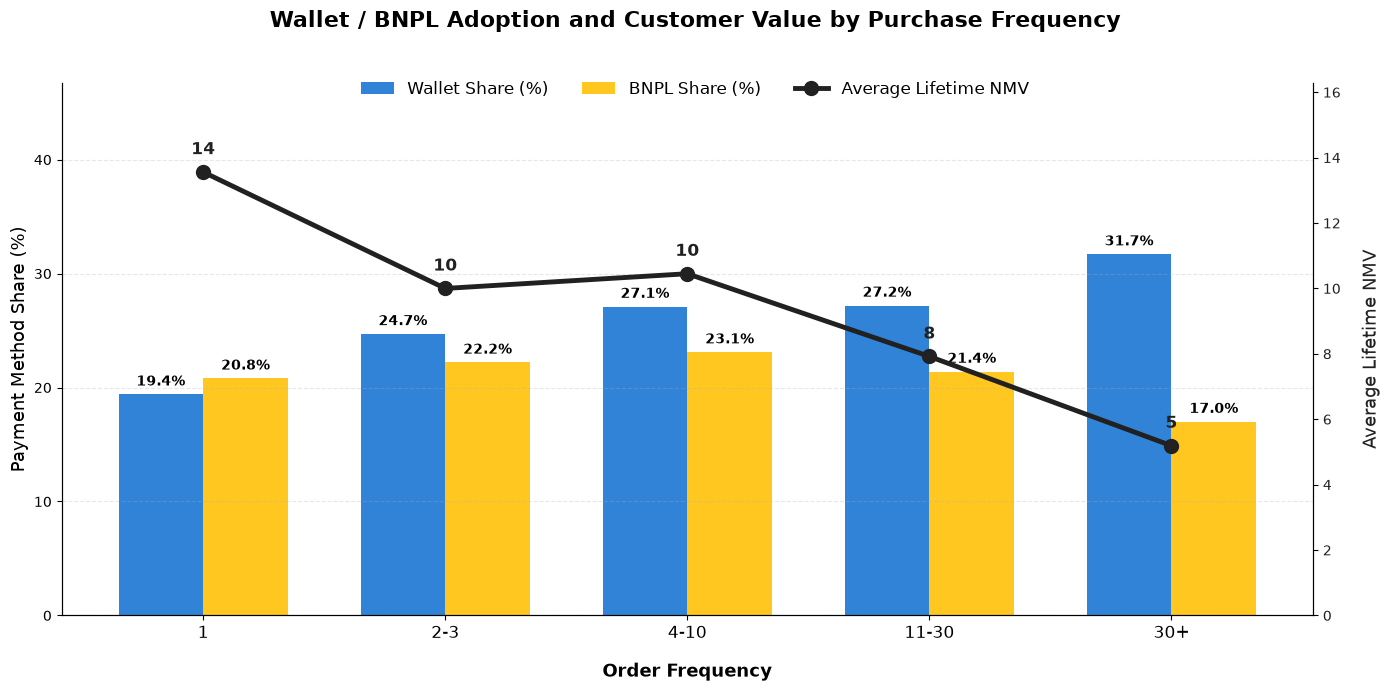

In [95]:
def assign_bucket(orders):
    if orders == 1:
        return "1"
    elif 2 <= orders <= 3:
        return "2-3"
    elif 4 <= orders <= 10:
        return "4-10"
    elif 11 <= orders <= 30:
        return "11-30"
    else:
        return "30+"


df_master_data["order_bucket"] = df_master_data["order"].apply(assign_bucket)

bucket_order = ["1", "2-3", "4-10", "11-30", "30+"]

df_master_data["order_bucket"] = pd.Categorical(
    df_master_data["order_bucket"],
    categories=bucket_order,
    ordered=True,
)

df_master_data["is_wallet"] = (
    df_master_data["payment_method"] == "Wallet"
).astype(int)

df_master_data["is_bnpl"] = (
    df_master_data["payment_method"] == "BNPL"
).astype(int)

df_bucket_summary = (
    df_master_data.groupby("order_bucket", observed=False)
    .agg(
        total_orders=("order_id", "count"),
        wallet_orders=("is_wallet", "sum"),
        bnpl_orders=("is_bnpl", "sum"),
        avg_nmv=("net_merchant_value", "mean"),
    )
    .reset_index()
)

df_bucket_summary["wallet_share"] = (
    df_bucket_summary["wallet_orders"]
    / df_bucket_summary["total_orders"]
) * 100

df_bucket_summary["bnpl_share"] = (
    df_bucket_summary["bnpl_orders"]
    / df_bucket_summary["total_orders"]
) * 100

df_bucket_summary["wallet_share"] = df_bucket_summary["wallet_share"].round(1)
df_bucket_summary["bnpl_share"] = df_bucket_summary["bnpl_share"].round(1)
df_bucket_summary["avg_nmv"] = df_bucket_summary["avg_nmv"].round(2)

df_plot = df_bucket_summary[
    ["order_bucket", "wallet_share", "bnpl_share", "avg_nmv"]
]

x = np.arange(len(df_plot["order_bucket"]))
width = 0.35

fig, ax1 = plt.subplots(figsize=(14, 7))

fig.suptitle(
    "Wallet / BNPL Adoption and Customer Value by Purchase Frequency",
    fontsize=16,
    fontweight="bold",
    y=0.98,
)

bar1 = ax1.bar(
    x - width / 2,
    df_plot["wallet_share"],
    width,
    label="Wallet Share (%)",
    color="#1976D2",
    alpha=0.9,
)

bar2 = ax1.bar(
    x + width / 2,
    df_plot["bnpl_share"],
    width,
    label="BNPL Share (%)",
    color="#FFC107",
    alpha=0.9,
)

ax1.set_xlabel(
    "Order Frequency",
    fontsize=13,
    fontweight="bold",
    labelpad=15,
)

ax1.set_ylabel(
    "Payment Method Share (%)",
    fontsize=13,
)

ax1.set_xticks(x)
ax1.set_xticklabels(df_plot["order_bucket"], fontsize=12)

ax1.set_ylim(
    0,
    max(df_plot[["wallet_share", "bnpl_share"]].max()) + 15,
)

for bar in bar1 + bar2:
    height = bar.get_height()

    ax1.annotate(
        f"{height}%",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

ax2 = ax1.twinx()

line1 = ax2.plot(
    x,
    df_plot["avg_nmv"],
    color="#212121",
    marker="o",
    linewidth=3.5,
    markersize=10,
    label="Average Lifetime NMV",
    zorder=5,
)

ax2.set_ylabel(
    "Average Lifetime NMV",
    fontsize=13,
    color="#212121",
    labelpad=15,
)

ax2.tick_params(axis="y", labelcolor="#212121")
ax2.set_ylim(0, df_plot["avg_nmv"].max() * 1.2)

for i, v in enumerate(df_plot["avg_nmv"]):
    ax2.annotate(
        f"{v:,.0f}",
        xy=(i, v),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold",
        color="#212121",
    )

ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

lines_labels = [
    ax.get_legend_handles_labels()
    for ax in [ax1, ax2]
]

lines, labels = [
    sum(lol, [])
    for lol in zip(*lines_labels)
]

fig.legend(
    lines,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.9),
    ncol=3,
    frameon=False,
    fontsize=12,
)

ax1.yaxis.grid(
    True,
    linestyle="--",
    alpha=0.3,
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### Credit Instalment Clean Growth among all the payment-method

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('analyse_data_support/profit_with_category.csv')

df['net_position'] = df['user_payment_fee'] - df['platform_discount']
df['platform_discount_pct'] = (df['platform_discount'] / df['gross_merchant_value']) * 100
df['seller_discount_pct'] = (df['seller_discount'] / df['gross_merchant_value']) * 100

s4_data = df.groupby('payment_method').agg(
    avg_discount_pct=('platform_discount_pct', 'mean'),
    aov=('gross_merchant_value', 'mean'),
    total_net_profit=('net_position', 'sum'),
    volume=('order_id', 'count')
).reset_index()
s4_data


,payment_method,avg_discount_pct,aov,total_net_profit,volume
0,BNPL,13.009479,7.194252,-1186.426978,1868
1,Cash,13.546841,5.275525,-1501.822542,3729
2,Credit,10.891583,8.502965,-283.476464,1080
3,Credit Installment,6.911396,41.560982,961.344748,286
4,Wallet,13.279703,5.345578,-1346.122621,2972


### Where Credit-Instalment should be invested in: Beauty or Fashion ? 

/var/folders/qm/b_xpc54n1l148zj7x68wqbj80000gn/T/ipykernel_87702/1417167787.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


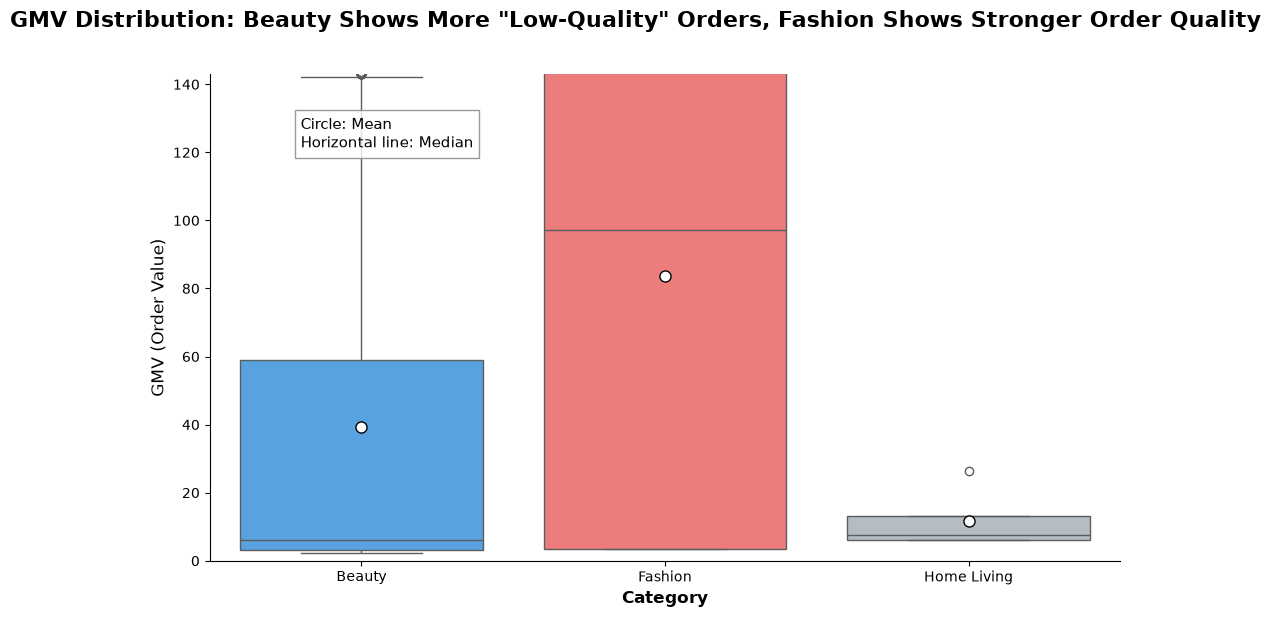

In [91]:
df_ci = df[df["payment_method"] == "Credit Installment"]

s5_stats = (
    df_ci.groupby("category")["gross_merchant_value"]
    .agg(["count", "mean", "median"])
    .round(2)
)

fig, ax = plt.subplots(figsize=(10, 6))

fig.suptitle(
    'GMV Distribution: Beauty Shows More "Low-Quality" Orders, Fashion Shows Stronger Order Quality',
    fontsize=16,
    fontweight="bold",
    y=1.02,
)

sns.boxplot(
    data=df_ci[df_ci["category"].isin(["Beauty", "Fashion", "Home Living"])],
    x="category",
    y="gross_merchant_value",
    palette=["#42A5F5", "#FF6B6B", "#B0BEC5"],
    ax=ax,
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": "8",
    },
)

ax.set_xlabel("Category", fontsize=12, fontweight="bold")
ax.set_ylabel("GMV (Order Value)", fontsize=12)
ax.set_ylim(0, df_ci["gross_merchant_value"].quantile(0.95))

plt.text(
    0.1,
    0.85,
    "Circle: Mean\nHorizontal line: Median",
    transform=ax.transAxes,
    fontsize=11,
    bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray"),
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Seller Discount and Platform Discount: No-correlation

Correlation between Seller Discount and Platform Discount: 0.027


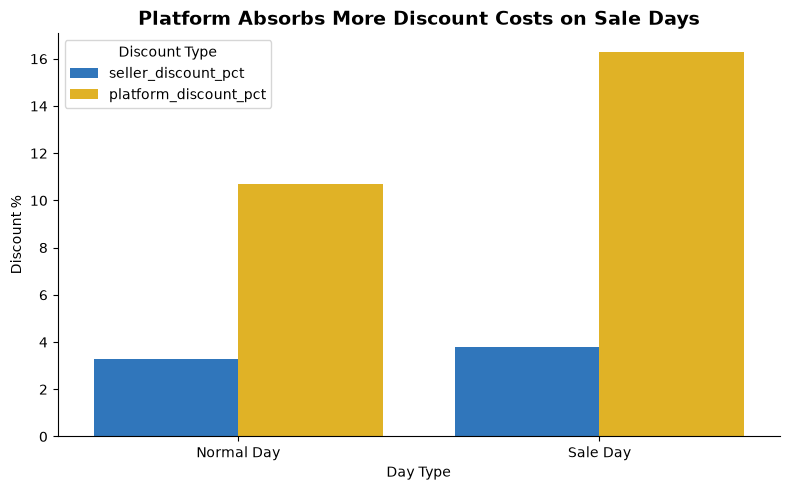

In [92]:

df["create_date"] = pd.to_datetime(df["create_date"])

df["is_sale_day"] = np.where(
    (df["create_date"].dt.day == df["create_date"].dt.month)
    | (df["create_date"].dt.day.isin([15, 25])),
    "Sale Day",
    "Normal Day",
)

corr = df["seller_discount_pct"].corr(df["platform_discount_pct"])

print(
    f"Correlation between Seller Discount and Platform Discount: {corr:.3f}"
)

s6_data = (
    df.groupby("is_sale_day")[
        ["seller_discount_pct", "platform_discount_pct"]
    ]
    .mean()
    .reset_index()
)

s6_melted = s6_data.melt(
    id_vars="is_sale_day",
    var_name="Discount Type",
    value_name="Discount %",
)

fig6, ax6 = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=s6_melted,
    x="is_sale_day",
    y="Discount %",
    hue="Discount Type",
    palette=["#1976D2", "#FFC107"],
    ax=ax6,
)

ax6.set_title(
    "Platform Absorbs More Discount Costs on Sale Days",
    fontsize=14,
    fontweight="bold",
)

ax6.set_xlabel("Day Type")
ax6.set_ylabel("Discount %")

ax6.spines["top"].set_visible(False)
ax6.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

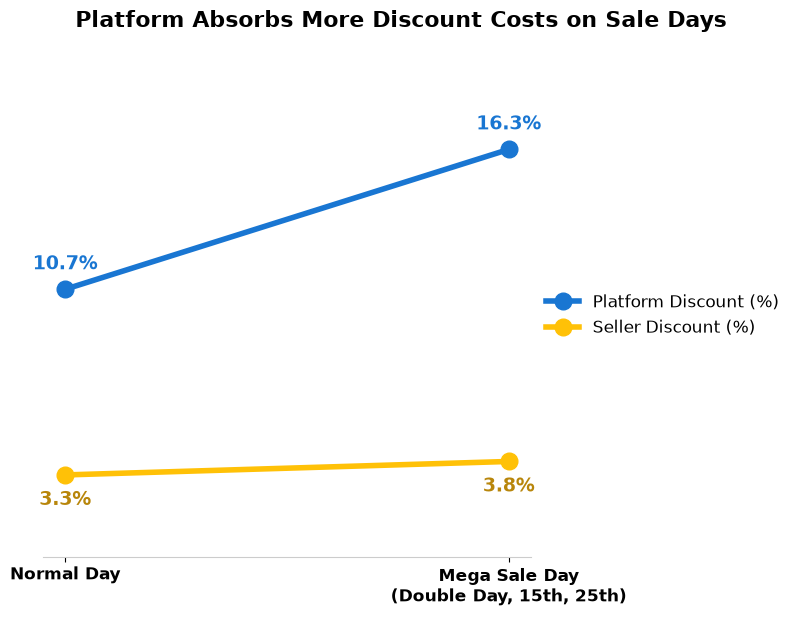

In [93]:
df["create_date"] = pd.to_datetime(df["create_date"])

is_double_day = df["create_date"].dt.day == df["create_date"].dt.month
is_mid_or_payday = df["create_date"].dt.day.isin([15, 25])

df["is_sale_day"] = np.where(
    is_double_day | is_mid_or_payday,
    "Mega Sale Day",
    "Normal Day",
)

df["platform_discount_pct"] = (
    df["platform_discount"] / df["gross_merchant_value"]
) * 100

df["seller_discount_pct"] = (
    df["seller_discount"] / df["gross_merchant_value"]
) * 100

df["seller_discount_pct"] = (
    df["seller_discount_pct"]
    .replace([np.inf, -np.inf], 0)
    .fillna(0)
)

df["platform_discount_pct"] = (
    df["platform_discount_pct"]
    .replace([np.inf, -np.inf], 0)
    .fillna(0)
)

df_summary = (
    df.groupby("is_sale_day")[
        ["platform_discount_pct", "seller_discount_pct"]
    ]
    .mean()
    .reset_index()
)

df_summary["is_sale_day"] = pd.Categorical(
    df_summary["is_sale_day"],
    categories=["Normal Day", "Mega Sale Day"],
    ordered=True,
)

df_summary = df_summary.sort_values("is_sale_day").reset_index(drop=True)


fig, ax = plt.subplots(figsize=(8, 6))

fig.suptitle(
    "Platform Absorbs More Discount Costs on Sale Days",
    fontsize=16,
    fontweight="bold",
    y=1.02,
)

x = [0, 1]

y_platform = df_summary["platform_discount_pct"].values
y_seller = df_summary["seller_discount_pct"].values

ax.plot(
    x,
    y_platform,
    marker="o",
    markersize=12,
    color="#1976D2",
    linewidth=4,
    label="Platform Discount (%)",
)

ax.plot(
    x,
    y_seller,
    marker="o",
    markersize=12,
    color="#FFC107",
    linewidth=4,
    label="Seller Discount (%)",
)

for i, val in enumerate(y_platform):
    ax.text(
        x[i],
        val + 0.8,
        f"{val:.1f}%",
        color="#1976D2",
        fontweight="bold",
        fontsize=14,
        ha="center",
    )

for i, val in enumerate(y_seller):
    ax.text(
        x[i],
        val - 1.2,
        f"{val:.1f}%",
        color="#B8860B",
        fontweight="bold",
        fontsize=14,
        ha="center",
    )

ax.set_xticks(x)

ax.set_xticklabels(
    [
        "Normal Day",
        "Mega Sale Day\n(Double Day, 15th, 25th)",
    ],
    fontsize=12,
    fontweight="bold",
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#cccccc")

ax.get_yaxis().set_visible(False)

ax.set_ylim(0, y_platform.max() + 3)

ax.legend(
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    fontsize=12,
    frameon=False,
)

plt.tight_layout()
plt.show()

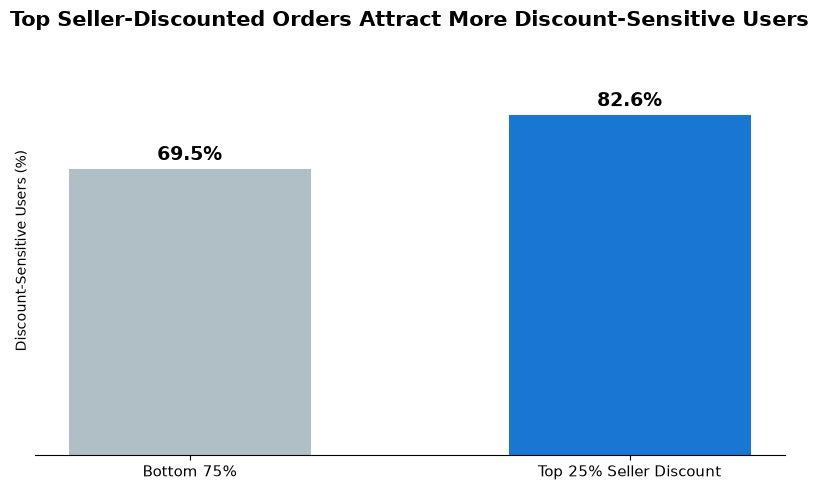

Platform Discount Overlap with Top 25% Seller Discount: $1,239


In [94]:
top_25_seller_threshold = df["seller_discount_pct"].quantile(0.75)

df["seller_discount_bucket"] = np.where(
    df["seller_discount_pct"] >= top_25_seller_threshold,
    "Top 25% Seller Discount",
    "Bottom 75%",
)

overlap_discount = df[
    df["seller_discount_bucket"] == "Top 25% Seller Discount"
]["platform_discount"].sum()

s7_overlap = (
    df.groupby("seller_discount_bucket")["seg_discount_sensitive_user"]
    .mean()
    .mul(100)
    .reindex(["Bottom 75%", "Top 25% Seller Discount"])
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    s7_overlap.index,
    s7_overlap.values,
    color=["#B0BEC5", "#1976D2"],
    width=0.55,
)

for bar, value in zip(bars, s7_overlap.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=14,
        fontweight="bold",
    )

ax.set_title(
    "Top Seller-Discounted Orders Attract More Discount-Sensitive Users",
    fontsize=15,
    fontweight="bold",
    pad=15,
)

ax.set_ylabel("Discount-Sensitive Users (%)")
ax.set_ylim(0, max(s7_overlap.values) * 1.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="y", left=False, labelleft=False)
ax.tick_params(axis="x", labelsize=11)

plt.tight_layout()
plt.show()

print(
    f"Platform Discount Overlap with Top 25% Seller Discount: "
    f"${overlap_discount:,.0f}"
)

In [96]:
ci_users = df.loc[
    df["payment_method"] == "Credit Installment",
    "user_id",
].unique()

df_ci_users = df[df["user_id"].isin(ci_users)]

print(
    f"{len(ci_users):,} customers have used Credit Installment. "
    f"Across their lifetime, they generated {len(df_ci_users):,} orders."
)

cross_method = (
    df_ci_users.groupby("payment_method")
    .agg(
        volume=("order_id", "count"),
        aov=("gross_merchant_value", "mean"),
    )
    .reset_index()
)

print("\nCross-payment behavior among CI users:")
display(cross_method)

pivot_cross_sell = df_ci_users.pivot_table(
    index="category",
    columns="payment_method",
    values="order_id",
    aggfunc="count",
    fill_value=0,
)

pivot_cross_sell = pivot_cross_sell[
    ["Credit Installment", "Wallet", "BNPL"]
]

pivot_cross_sell["Total_Ecosystem_Txns"] = (
    pivot_cross_sell["Wallet"]
    + pivot_cross_sell["BNPL"]
)

cross_sell_opportunity = pivot_cross_sell.sort_values(
    by="Total_Ecosystem_Txns",
    ascending=False,
)

print(
    "\nCross-sell opportunities among CI users "
    "(Wallet + BNPL transaction volume):"
)

display(cross_sell_opportunity)

142 customers have used Credit Installment. Across their lifetime, they generated 5,365 orders.

Cross-payment behavior among CI users:


,payment_method,volume,aov
0,BNPL,949,6.613163
1,Cash,2008,5.028628
2,Credit,529,7.802608
3,Credit Installment,286,41.560982
4,Wallet,1593,5.080176



Cross-sell opportunities among CI users (Wallet + BNPL transaction volume):


payment_method,Credit Installment,Wallet,BNPL,Total_Ecosystem_Txns
category,,,,
Beauty,265,1478,885,2363
Fashion,17,68,41,109
Home Living,4,47,22,69
Electronics,0,0,1,1
